# A tour of the models behind object detection and Argus

See what each model takes in, what it gives back, and how the project turns that into answers.
Everything runs on CPU with the project's own code (`src/`) and the sample files in `data/`.

| Step | Model | What it does | Licence | File |
| --- | --- | --- | --- | --- |
| 1 | **YOLOX** (Megvii) | finds objects: box + one of 80 COCO classes | Apache-2.0 | `models/yolox_*.onnx` |
| 2 | **Tracker** (no neural network) | links boxes frame to frame into one visit with an ID | ours | `src/argus/engine/tracker.py` |
| 3 | **YuNet** (OpenCV Zoo) | finds faces: box + 5 landmarks | MIT | `face_detection_yunet_2023mar.onnx` |
| 4 | **SFace** (OpenCV Zoo) | turns an aligned face into a 128-number *face print* | Apache-2.0 | `face_recognition_sface_2021dec.onnx` |
| 5 | **Pose**: ViTPose-B (or RTMPose-t for trials) | 17 body keypoints per person → posture, hands up, facing, clothing colours | Apache-2.0 | `pose_vitpose_b.onnx` |
| 6 | **CLIP** ViT-B/32 (OpenCLIP) | puts images and text in the same 512-number space, for search by description | MIT | `clip_image.onnx`, `clip_text.onnx` |

```text
camera frame ──► YOLOX ──► boxes ──► Tracker ──► tracks (visits)
                                        │
                     person crop ──► YuNet ──► face ──► SFace ──► face print ──► store
                     person crop ──► Pose ──► keypoints ──► posture, colours ──► store
                     object crop ──► CLIP image encoder ──────────────────────► store
question text ──────────────────► CLIP text encoder ──► compare with stored vectors
```

**Setup** (once, in `projects/argus`):

```bash
uv sync --group notebook
uv run -m argus.engine.download_model yolox_nano      # also yolox_tiny, yolox_s ... ; and: faces
uv run --group export -m argus.engine.export_clip     # optional, for the CLIP section (~600 MB)
uv run --group export -m argus.engine.export_pose     # optional, for the pose section (344 MB)
```

Then open this notebook in VS Code (kernel: the project's `.venv`) or run
`uv run --group notebook --with jupyterlab jupyter lab`.

In [ ]:
import sys
import time
from collections import defaultdict
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent  # notebooks/ or project

import cv2
import matplotlib.pyplot as plt
import numpy as np
MODELS, DATA = ROOT / "models", ROOT / "data"

from argus.engine.detector import COCO_CLASSES, YoloxOnnxDetector, decode_yolox, draw_detections, letterbox, nms
from argus.engine.faces import LIKELY_SAME_PERSON, SAME_PERSON_THRESHOLD, FaceEngine, choose_face
from argus.engine.tracker import Tracker

plt.rcParams.update({"figure.dpi": 90, "axes.titlesize": 10})
SPEED = {}  # ms per call, filled in as we go


def show(*images, titles=None, size=4.5, cmap=None):
    # Show BGR / grey images side by side.
    fig, axes = plt.subplots(1, len(images), figsize=(size * len(images), size))
    for ax, im, title in zip(np.atleast_1d(axes), images, titles or [""] * len(images)):
        ax.imshow(im if im.ndim == 2 else cv2.cvtColor(im, cv2.COLOR_BGR2RGB), cmap=cmap)
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    plt.show()


def timed(fn, *args, runs=5):
    # Average milliseconds per call (after one warm-up call) and the last result.
    result = fn(*args)
    start = time.perf_counter()
    for _ in range(runs):
        result = fn(*args)
    return (time.perf_counter() - start) / runs * 1000, result


for f in sorted(MODELS.glob("*.onnx")):
    print(f"{f.name:42} {f.stat().st_size / 1e6:7.1f} MB")

face_detection_yunet_2023mar.onnx              0.2 MB
face_recognition_sface_2021dec.onnx           38.7 MB
pose_rtmpose_t.onnx                           13.4 MB
pose_vitpose_b.onnx                          343.9 MB
yolox_l.onnx                                 216.7 MB
yolox_m.onnx                                 101.3 MB
yolox_nano.onnx                                3.7 MB
yolox_s.onnx                                  35.9 MB
yolox_tiny.onnx                               20.2 MB


## 1. YOLOX: finding objects

YOLOX is a one-stage detector: one pass over the image gives a guess for **every cell of three
grids** at once. The project runs it through ONNX Runtime; `src/argus/engine/detector.py` does the rest in
numpy, so it ports to C++ line for line.

### 1.1 What goes in

A fixed-size square (416×416 for nano/tiny, 640×640 for s/m/l/x). The photo is resized to fit
**without stretching**, and the leftover is padded with grey (114). That's the *letterbox*.

input  images: [1, 3, 416, 416]   (batch, colour channels, height, width)
output output: [1, 3549, 85]


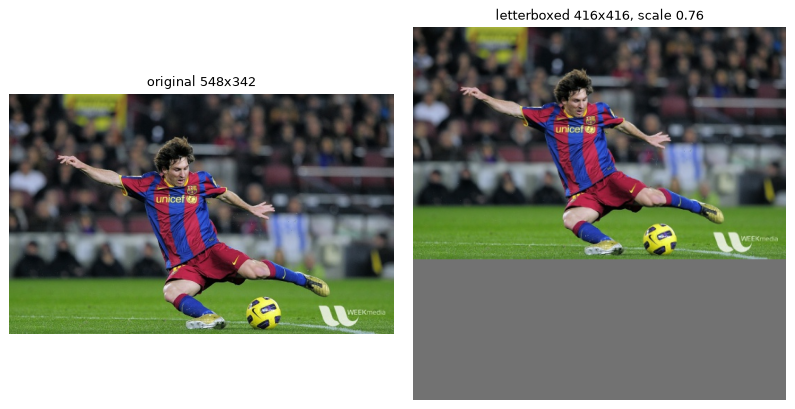

In [2]:
det = YoloxOnnxDetector(MODELS / "yolox_tiny.onnx", conf_threshold=0.35)
inp, out = det.session.get_inputs()[0], det.session.get_outputs()[0]
print(f"input  {inp.name}: {inp.shape}   (batch, colour channels, height, width)")
print(f"output {out.name}: {out.shape}")

image = cv2.imread(str(DATA / "messi5.jpg"))
blob, ratio = letterbox(image, det.input_size)
show(image, blob.transpose(1, 2, 0).astype(np.uint8),
     titles=[f"original {image.shape[1]}x{image.shape[0]}",
             f"letterboxed {det.input_size[1]}x{det.input_size[0]}, scale {ratio:.2f}"])

### 1.2 What comes out

One row per grid cell. The grids have one cell every 8, 16 and 32 pixels (*strides*): fine
cells for small objects, coarse ones for big objects. Each row has 85 numbers:

| Columns | Meaning |
| --- | --- |
| 0–3 | box centre x, y and width, height, *relative to the cell* (`decode_yolox` converts them to pixels) |
| 4 | objectness: "is there an object centred here?" (0–1) |
| 5–84 | probability of each of the 80 COCO classes |

Score of a class in a cell = objectness × class probability.

In [3]:
size = det.input_size[0]
raw = det.session.run(None, {det.input_name: blob[None]})[0][0]
print("raw output:", raw.shape)
for stride in (8, 16, 32):
    n = size // stride
    print(f"  stride {stride:2}: {n}x{n} grid = {n * n:5} rows")
print(f"  total          = {sum((size // s) ** 2 for s in (8, 16, 32))} rows")
print(f"\n{len(COCO_CLASSES)} classes:", ", ".join(COCO_CLASSES[:12]), "...")

raw output: (3549, 85)
  stride  8: 52x52 grid =  2704 rows
  stride 16: 26x26 grid =   676 rows
  stride 32: 13x13 grid =   169 rows
  total          = 3549 rows

80 classes: person, bicycle, car, motorcycle, airplane, bus, train, truck, boat, traffic light, fire hydrant, stop sign ...


Where does the model "see" something? The best class score of every cell, drawn per grid.
People light up on the fine grids, close-up things on the coarse one.

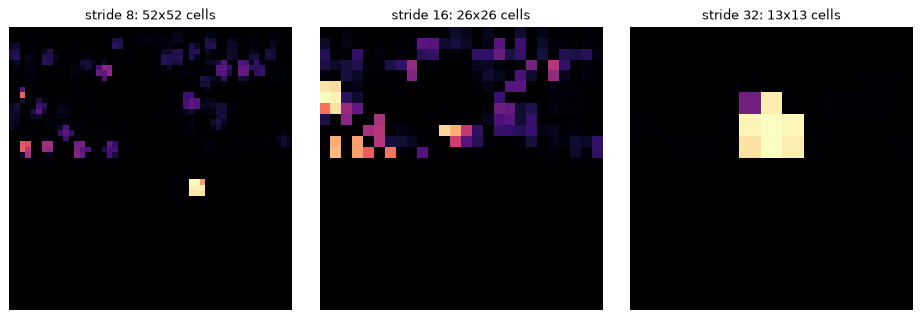

In [4]:
scores = raw[:, 4:5] * raw[:, 5:]          # (rows, 80)
best = scores.max(1)
maps, start = [], 0
for stride in (8, 16, 32):
    n = size // stride
    maps.append(best[start:start + n * n].reshape(n, n))
    start += n * n
show(*maps, titles=[f"stride {s}: {m.shape[0]}x{m.shape[1]} cells" for s, m in zip((8, 16, 32), maps)],
     size=3.5, cmap="magma")

### 1.3 From thousands of guesses to a few boxes

1. Keep rows whose score is above `conf_threshold`.
2. Several neighbouring cells usually find the same object. **NMS** (non-maximum suppression)
   keeps the highest-scoring box and drops the others that overlap it by more than
   `nms_threshold` (IoU, overlap ÷ union).

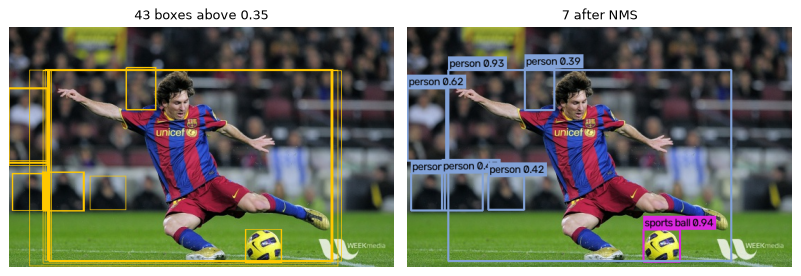

sports ball  0.94  box (337, 288) - (388, 335)
person       0.93  box (58, 62) - (462, 333)
person       0.62  box (5, 209) - (54, 261)
person       0.62  box (0, 88) - (55, 190)
person       0.47  box (50, 207) - (107, 262)
person       0.42  box (116, 212) - (166, 260)
person       0.39  box (168, 58) - (209, 118)


In [5]:
preds = decode_yolox(raw, det.input_size)
class_ids = scores.argmax(1)
mask = best > det.conf_threshold
cx, cy, w, h = preds[mask, :4].T
candidates = np.stack([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2], 1) / ratio

before = image.copy()
for x1, y1, x2, y2 in candidates.astype(int):
    cv2.rectangle(before, (x1, y1), (x2, y2), (0, 200, 255), 1)
SPEED["YOLOX-Tiny (416)"], detections = timed(det.detect, image)
after = draw_detections(image.copy(), detections)
show(before, after, titles=[f"{mask.sum()} boxes above {det.conf_threshold}",
                            f"{len(detections)} after NMS"])
for d in detections:
    print(f"{d.label:12} {d.score:.2f}  box ({d.x1:.0f}, {d.y1:.0f}) - ({d.x2:.0f}, {d.y2:.0f})")

### 1.4 The two knobs

**Confidence threshold**: lower finds more (and more mistakes), higher finds fewer.
The config uses 0.25–0.35; the tracker can still use weaker boxes to keep a known track alive.

In [6]:
for threshold in (0.1, 0.25, 0.35, 0.5, 0.7):
    det.conf_threshold = threshold
    found = det.detect(image)
    print(f"conf {threshold:.2f}: {len(found):2} boxes  {sorted({d.label for d in found})}")
det.conf_threshold = 0.35

conf 0.10: 29 boxes  ['person', 'sports ball']
conf 0.25: 13 boxes  ['person', 'sports ball']
conf 0.35:  7 boxes  ['person', 'sports ball']
conf 0.50:  4 boxes  ['person', 'sports ball']
conf 0.70:  2 boxes  ['person', 'sports ball']


**Per-class vs class-agnostic NMS.** By default NMS runs per class, so one animal can come
out as both *dog* and *cat*. `class_agnostic_nms: true` (used in the configs) lets the best
label win.

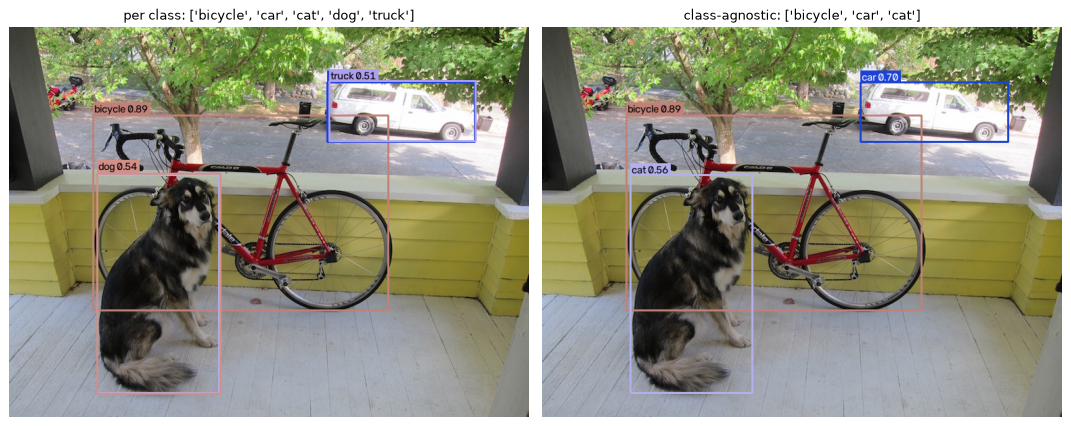

In [7]:
dog = cv2.imread(str(DATA / "dog.jpg"))
per_class = YoloxOnnxDetector(MODELS / "yolox_tiny.onnx", conf_threshold=0.35)
agnostic = YoloxOnnxDetector(MODELS / "yolox_tiny.onnx", conf_threshold=0.35, class_agnostic_nms=True)
a, b = per_class.detect(dog), agnostic.detect(dog)
show(draw_detections(dog.copy(), a), draw_detections(dog.copy(), b),
     titles=[f"per class: {[d.label for d in a]}", f"class-agnostic: {[d.label for d in b]}"], size=6)

### 1.5 Model sizes: speed vs accuracy on this CPU

Same code, different file. COCO accuracy (mAP 0.5:0.95) from the YOLOX paper.

yolox_x: not downloaded (uv run -m argus.engine.download_model yolox_x)
model       input     MB COCO mAP  ms/frame boxes
yolox_nano    416    3.7     25.8      10.4     8
yolox_tiny    416   20.2     32.8      22.5     7
yolox_s       640   35.9     40.5      70.3     6
yolox_m       640  101.3     47.2     171.7     7
yolox_l       640  216.7     50.1     382.8     7


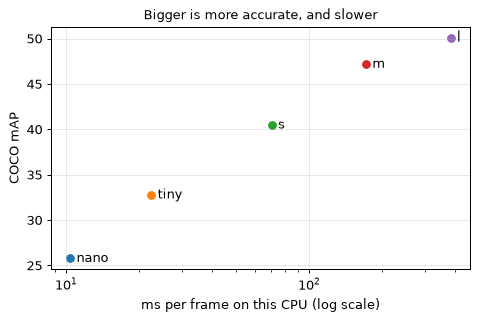

In [8]:
COCO_MAP = {"yolox_nano": 25.8, "yolox_tiny": 32.8, "yolox_s": 40.5, "yolox_m": 47.2,
            "yolox_l": 50.1, "yolox_x": 51.5}
rows = []
for name, map_ in COCO_MAP.items():
    path = MODELS / f"{name}.onnx"
    if not path.exists():
        print(f"{name}: not downloaded (uv run -m argus.engine.download_model {name})")
        continue
    model = YoloxOnnxDetector(path, conf_threshold=0.35, class_agnostic_nms=True)
    ms, found = timed(model.detect, image, runs=3)
    rows.append((name, model.input_size[0], path.stat().st_size / 1e6, map_, ms, len(found)))

print(f"{'model':11} {'input':>5} {'MB':>6} {'COCO mAP':>8} {'ms/frame':>9} {'boxes':>5}")
for name, inp_size, mb, map_, ms, n in rows:
    print(f"{name:11} {inp_size:5} {mb:6.1f} {map_:8.1f} {ms:9.1f} {n:5}")

fig, ax = plt.subplots(figsize=(6, 3.5))
for name, _, _, map_, ms, _ in rows:
    ax.scatter(ms, map_)
    ax.annotate(name.replace("yolox_", ""), (ms, map_), textcoords="offset points", xytext=(5, -3))
ax.set_xscale("log")
ax.set_xlabel("ms per frame on this CPU (log scale)")
ax.set_ylabel("COCO mAP")
ax.set_title("Bigger is more accurate, and slower")
ax.grid(alpha=0.3)
plt.show()

## 2. The tracker: from boxes to visits

Not a neural network: `src/argus/engine/tracker.py` (ByteTrack-style) matches each new box to the box a
track had in the previous frame, by overlap (IoU), after moving it by its last velocity.

- A track gets an **ID** only after `min_hits` matches (no IDs for one-frame flukes).
- Weak boxes (below `track_threshold`) can't start a track, but keep an existing one alive.
- A track survives `max_missed` frames without a box (someone walking behind a pillar).

One track = one visit: that's what Argus counts ("how many people came in today") and embeds.

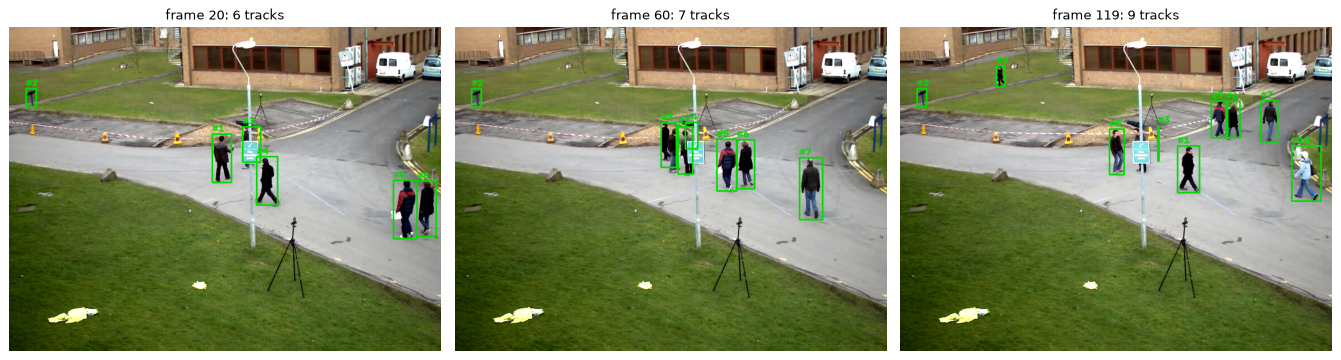

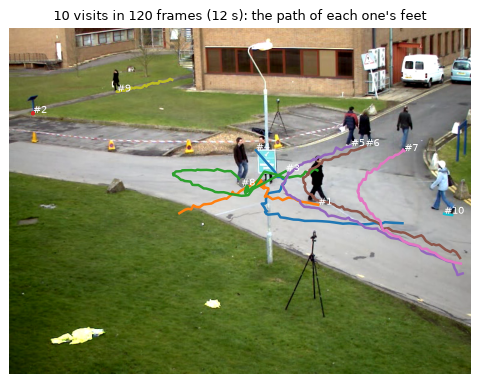

In [9]:
cap = cv2.VideoCapture(str(DATA / "vtest.avi"))
people = YoloxOnnxDetector(MODELS / "yolox_nano.onnx", conf_threshold=0.25, classes=["person"])
tracker = Tracker()
paths, shots = defaultdict(list), []
for i in range(120):
    ok, frame = cap.read()
    if not ok:
        break
    tracks, _ = tracker.update(people.detect(frame))
    for t in tracks:
        x1, y1, x2, y2 = t.box
        paths[t.id].append(((x1 + x2) / 2, y2))  # feet position
    if i in (20, 60, 119):
        drawn = frame.copy()
        for t in tracks:
            x1, y1, x2, y2 = t.box.astype(int)
            cv2.rectangle(drawn, (x1, y1), (x2, y2), (0, 220, 0), 2)
            cv2.putText(drawn, f"#{t.id}", (x1, y1 - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 220, 0), 2)
        shots.append((drawn, f"frame {i}: {len(tracks)} tracks"))
cap.release()
show(*[s[0] for s in shots], titles=[s[1] for s in shots], size=5)

fig, ax = plt.subplots(figsize=(7, 5))
ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
for track_id, pts in paths.items():
    xs, ys = zip(*pts)
    ax.plot(xs, ys, lw=2)
    ax.text(xs[-1], ys[-1], f"#{track_id}", color="white", fontsize=8)
ax.set_title(f"{len(paths)} visits in 120 frames (12 s): the path of each one's feet")
ax.axis("off")
plt.show()

## 3. YuNet: finding faces

A tiny face detector (0.2 MB, run by OpenCV's `FaceDetectorYN`). For each face it returns
**15 numbers**:

| Numbers | Meaning |
| --- | --- |
| 0–3 | box: x, y, width, height |
| 4–13 | 5 landmarks (x, y): right eye, left eye, nose tip, right and left mouth corner |
| 14 | confidence |

The landmarks matter twice: SFace uses them to straighten the face, and the project uses
the nose position between the eyes to measure how far the head is **turned** (`Face.turn`).

messi5.jpg -> [225.8  93.3  30.9  39.8 239.3 106.4 251.  106.6 248.3 114.1 241.2 120.8
 250.6 122.    0.9]
basketball2.png -> [ 70.7  91.5  32.7  41.9  83.7 106.1  97.8 106.1  93.9 114.5  85.5 123.3
  96.8 122.7   0.9]


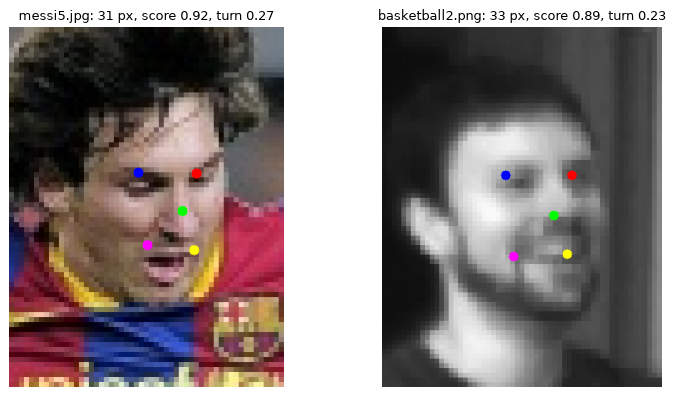

dots: right eye, left eye, nose, mouth R, mouth L (blue, red, green, magenta, yellow)


In [10]:
faces = FaceEngine(MODELS / "face_detection_yunet_2023mar.onnx",
                   MODELS / "face_recognition_sface_2021dec.onnx", min_face_size=10)
NAMES = ["right eye", "left eye", "nose", "mouth R", "mouth L"]
COLOURS = [(255, 0, 0), (0, 0, 255), (0, 255, 0), (255, 0, 255), (0, 255, 255)]

found = {}
panels = []
for name in ("messi5.jpg", "basketball2.png"):
    img = cv2.imread(str(DATA / name))
    SPEED["YuNet (whole image)"], fs = timed(faces.detect, img)
    found[name] = (img, fs)
    for f in fs:
        crop = faces.crop(img, f, margin=0.4).copy()
        x0 = max(0, f.box[0] - f.box[2] * 0.4)
        y0 = max(0, f.box[1] - f.box[3] * 0.4)
        crop = cv2.resize(crop, None, fx=6, fy=6, interpolation=cv2.INTER_NEAREST)
        for k in range(5):
            px, py = f.landmarks[4 + 2 * k] - x0, f.landmarks[5 + 2 * k] - y0
            cv2.circle(crop, (int(px * 6), int(py * 6)), 6, COLOURS[k], -1)
        panels.append((crop, f"{name}: {f.size:.0f} px, score {f.score:.2f}, turn {f.turn:.2f}"))
        print(name, "->", np.round(f.landmarks[:15], 1))
show(*[p[0] for p in panels], titles=[p[1] for p in panels])
print("dots:", ", ".join(f"{n}" for n in NAMES), "(blue, red, green, magenta, yellow)")

Note the size: these faces are only ~30 pixels tall. CCTV faces are often that small or
smaller, which is why the project crops faces from the **main stream** (full resolution) when
it can, and keeps the best 5 per visit.

## 4. SFace: the face print

1. **Align**: rotate and scale the face so the eyes and mouth land on fixed spots of a
   112×112 image (`alignCrop`, using YuNet's landmarks).
2. **Embed**: SFace turns it into 128 numbers. We scale them to length 1, so comparing two
   faces is a dot product: the **cosine similarity**, from -1 to 1.

| Similarity | The project says |
| --- | --- |
| below 0.363 | different people (SFace's published threshold, set on clear photos) |
| 0.363 – 0.45 | **possible** match: check the thumbnail |
| above 0.45 | **likely** the same person |

Face prints are biometric data: only on cameras a client approved, deleted after
`face_retention_days`. Here we only use the public sample images.

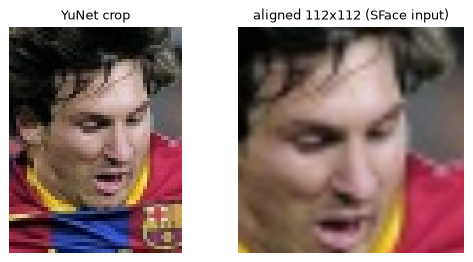

face print: 128 numbers, length 1.00
quality: size 31 px, sharpness 85, turn 0.27 -> value 0.20


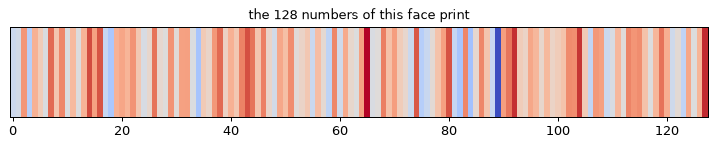

In [11]:
img, (face,) = found["messi5.jpg"][0], found["messi5.jpg"][1][:1]
aligned = faces._recognizer.alignCrop(img, face.landmarks)
SPEED["SFace (one face)"], (vector, quality) = timed(faces.analyze, img, face)
show(faces.crop(img, face), aligned, titles=["YuNet crop", "aligned 112x112 (SFace input)"], size=3)
print(f"face print: {vector.shape[0]} numbers, length {np.linalg.norm(vector):.2f}")
print(f"quality: size {quality.size:.0f} px, sharpness {quality.sharpness:.0f}, turn {quality.turn:.2f}"
      f" -> value {quality.value:.2f}")

fig, ax = plt.subplots(figsize=(10, 1.3))
ax.imshow(vector[None, :], aspect="auto", cmap="coolwarm")
ax.set_yticks([])
ax.set_title("the 128 numbers of this face print")
plt.show()

### 4.1 Same person, worse picture

Real cameras blur, darken and shrink faces. We damage the same photo in different ways,
detect the face again, and compare its print with the original. This is why the recorder
refuses blurred, tiny or turned faces instead of storing them.

mirrored           similarity  0.92  likely    sharpness    83
darker (50%)       similarity  0.96  likely    sharpness    23
JPEG quality 15    similarity  0.59  likely    sharpness    53
Gaussian blur      similarity  0.70  likely    sharpness     5
motion blur        similarity  0.22  no match  sharpness    18
half resolution    similarity  0.74  likely    sharpness     9
third resolution   similarity  0.47  likely    sharpness     7
different person   similarity  0.28  no match  


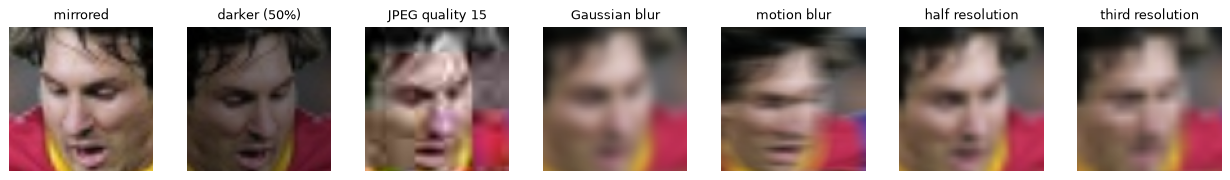

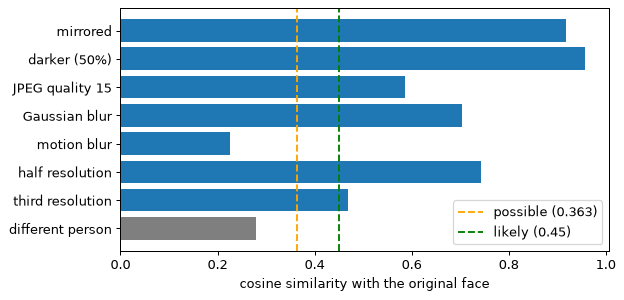

In [12]:
def motion_blur(im, length=9):
    kernel = np.zeros((length, length), np.float32)
    kernel[length // 2, :] = 1 / length
    return cv2.filter2D(im, -1, kernel)


def jpeg(im, q):
    return cv2.imdecode(cv2.imencode(".jpg", im, [cv2.IMWRITE_JPEG_QUALITY, q])[1], cv2.IMREAD_COLOR)


def shrink(im, factor):
    small = cv2.resize(im, None, fx=factor, fy=factor, interpolation=cv2.INTER_AREA)
    return cv2.resize(small, (im.shape[1], im.shape[0]), interpolation=cv2.INTER_LINEAR)


versions = {
    "mirrored": cv2.flip(img, 1),
    "darker (50%)": cv2.convertScaleAbs(img, alpha=0.5),
    "JPEG quality 15": jpeg(img, 15),
    "Gaussian blur": cv2.GaussianBlur(img, (0, 0), 1.5),
    "motion blur": motion_blur(img),
    "half resolution": shrink(img, 0.5),
    "third resolution": shrink(img, 0.33),
}
results, crops = [], []
for label, version in versions.items():
    fs = faces.detect(version)
    if not fs:
        results.append((label, None, None))
        continue
    v, q = faces.analyze(version, fs[0])
    results.append((label, float(v @ vector), q))
    crops.append((faces._recognizer.alignCrop(version, fs[0].landmarks), label))

other_img, other_faces = found["basketball2.png"]
other, _ = faces.analyze(other_img, other_faces[0])
results.append(("different person", float(other @ vector), None))

for label, sim, q in results:
    if sim is None:
        print(f"{label:18} face not found any more")
        continue
    verdict = ("likely" if sim >= LIKELY_SAME_PERSON else
               "possible" if sim >= SAME_PERSON_THRESHOLD else "no match")
    extra = f"sharpness {q.sharpness:5.0f}" if q else ""
    print(f"{label:18} similarity {sim:5.2f}  {verdict:9} {extra}")

show(*[c[0] for c in crops], titles=[c[1] for c in crops], size=2)
shown = [(l, s) for l, s, _ in results if s is not None]
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh([l for l, _ in shown], [s for _, s in shown],
        color=["tab:gray" if l == "different person" else "tab:blue" for l, _ in shown])
ax.axvline(SAME_PERSON_THRESHOLD, color="orange", ls="--", label=f"possible ({SAME_PERSON_THRESHOLD})")
ax.axvline(LIKELY_SAME_PERSON, color="green", ls="--", label=f"likely ({LIKELY_SAME_PERSON})")
ax.set_xlabel("cosine similarity with the original face")
ax.invert_yaxis()
ax.legend(loc="lower right")
plt.show()

### 4.2 Try your own photos

Two photos of the same person (or of two people), on your machine only: nothing is saved.
With several faces in a photo, set `FACE_A` / `FACE_B` (1 = leftmost).

In [13]:
PHOTO_A, PHOTO_B = None, None   # e.g. r"C:\path\to\photo1.jpg"
FACE_A, FACE_B = None, None

if PHOTO_A and PHOTO_B:
    picked = []
    for path, choice in ((PHOTO_A, FACE_A), (PHOTO_B, FACE_B)):
        photo = cv2.imread(str(path))
        face_ = choose_face(FaceEngine(MODELS / "face_detection_yunet_2023mar.onnx",
                                       MODELS / "face_recognition_sface_2021dec.onnx",
                                       min_face_size=20).photo_faces(photo), choice)
        if isinstance(face_, str):
            print(f"{path}: {face_}")
            break
        picked.append(face_)
    else:
        sim = float(picked[0].print @ picked[1].print)
        print(f"similarity {sim:.2f}:",
              "likely the same person" if sim >= LIKELY_SAME_PERSON else
              "possibly the same person" if sim >= SAME_PERSON_THRESHOLD else "no match")
else:
    print("Set PHOTO_A and PHOTO_B to compare two photos.")

Set PHOTO_A and PHOTO_B to compare two photos.


## 5. Body pose: what people were doing

A top-down pose model takes a **person crop** (the tracker's box, padded and resized to
256×192) and returns **17 keypoints** with a confidence each: nose, eyes, ears, shoulders,
elbows, wrists, hips, knees, ankles. The project uses it to store a few facts per person, about
once a second (`src/argus/engine/pose.py`, `src/argus/engine/pose_index.py`):

| Fact | Values | From |
| --- | --- | --- |
| posture | standing, sitting, crouching, lying | torso angle; thighs and feet against torso length |
| arms | down, one_up, both_up | wrists clearly above the head |
| facing | camera, side, away | shoulder order first, then nose and eyes |
| top / trousers colour | 11 names (red, blue, black...) | most common colour inside the torso and along the legs |

Two models, same code (told apart by their ONNX outputs):

| Model | Licence | Output | Get it |
| --- | --- | --- | --- |
| **ViTPose-B** "simple" | Apache-2.0, COCO-only training: **shippable** | 17 heatmaps of 64×48 | `uv run --group export -m argus.engine.export_pose` |
| RTMPose-t | Apache-2.0 code, but trained on 7 datasets, some research-only: **trials** | 2 × 17 vectors (SimCC: x and y) | `uv run -m argus.engine.download_model pose_rtmpose_t` |

In [14]:
from argus.engine.pose import PoseEstimator, describe, draw_skeleton, _legs_mask, _torso_mask

POSE_MODELS = [m for m in ("pose_vitpose_b", "pose_rtmpose_t") if (MODELS / f"{m}.onnx").exists()]
print("pose models here:", POSE_MODELS or "none: export or download one (see above)")
estimator = PoseEstimator(MODELS / f"{POSE_MODELS[0]}.onnx") if POSE_MODELS else None

pose models here: ['pose_vitpose_b', 'pose_rtmpose_t']


basketball2.png  standing  arms down     facing camera top black, trousers grey  (17/17 keypoints seen)
basketball2.png  unknown   arms down     facing away   top grey, trousers None  (13/17 keypoints seen)


messi5.jpg       crouching arms down     facing camera top blue, trousers None  (17/17 keypoints seen)
messi5.jpg       sitting   arms down     facing camera top grey, trousers grey  (15/17 keypoints seen)
messi5.jpg       unknown   arms down     facing camera top None, trousers None  (9/17 keypoints seen)


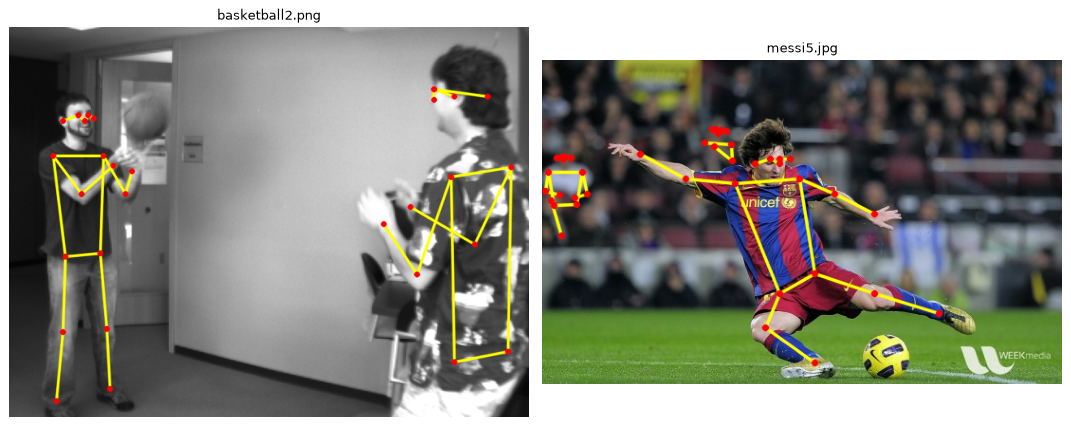

In [15]:
person_det = YoloxOnnxDetector(MODELS / "yolox_tiny.onnx", classes=["person"], class_agnostic_nms=True)
if estimator is not None:
    panels = []
    for name in ("basketball2.png", "messi5.jpg"):
        img = cv2.imread(str(DATA / name))
        boxes = [np.array([d.x1, d.y1, d.x2, d.y2]) for d in person_det.detect(img) if d.y2 - d.y1 > 60]
        drawn = img.copy()
        for box, kp in zip(boxes, estimator.estimate(img, boxes)):
            draw_skeleton(drawn, kp)
            f = describe(kp, img)
            print(f"{name:16} {f.posture:9} arms {f.arms:8} facing {f.facing:6} "
                  f"top {f.upper_colour}, trousers {f.lower_colour}  ({f.visible}/17 keypoints seen)")
        panels.append(drawn)
    show(*panels, titles=["basketball2.png", "messi5.jpg"], size=6)

The man on the right of the first image faces away: his **left** shoulder is on the image's
left. Models often still put a face on the back of a head, so the shoulders decide first.

### 5.1 The colour areas

Colours come from the clothes the keypoints outline, not from the whole box (which includes
background): the torso between shoulders and hips, and thick lines along the legs.

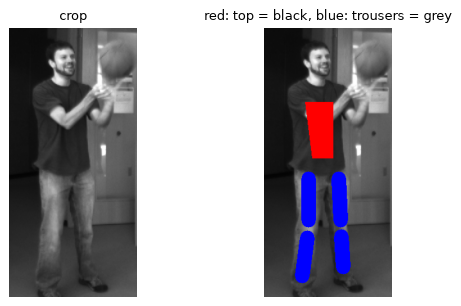

This image is black and white, so 'black' and 'grey' are right. At night (infrared) every camera is.


In [16]:
if estimator is not None:
    img = cv2.imread(str(DATA / "basketball2.png"))
    box = np.array([30, 83, 169, 479])
    kp = estimator.estimate(img, [box])[0]
    seen = kp[:, 2] >= 0.3
    torso = float(np.linalg.norm(kp[[11, 12], :2].mean(0) - kp[[5, 6], :2].mean(0)))
    overlay = img.copy()
    overlay[_torso_mask(img.shape, kp, seen).astype(bool)] = (0, 0, 255)
    overlay[_legs_mask(img.shape, kp, seen, torso).astype(bool)] = (255, 0, 0)
    f = describe(kp, img)
    show(img[60:480, 0:200], overlay[60:480, 0:200],
         titles=["crop", f"red: top = {f.upper_colour}, blue: trousers = {f.lower_colour}"], size=3.5)
    print("This image is black and white, so 'black' and 'grey' are right. At night (infrared) every camera is.")

### 5.2 Speed: the price of the clean licence

In [17]:
img = cv2.imread(str(DATA / "basketball2.png"))
box = np.array([30, 83, 169, 479])
for m in POSE_MODELS:
    est = PoseEstimator(MODELS / f"{m}.onnx")
    ms, _ = timed(est.estimate, img, [box], runs=3)
    ms8, _ = timed(est.estimate, img, [box] * 8, runs=2)
    SPEED[f"{m} (one person)"] = ms
    print(f"{m:16} {ms:6.1f} ms for one person, {ms8 / 8:6.1f} ms per person in a batch of 8")

pose_vitpose_b    101.6 ms for one person,   86.6 ms per person in a batch of 8


pose_rtmpose_t      5.1 ms for one person,    3.5 ms per person in a batch of 8


### 5.3 The whole system: record, store smartly, search

The pipeline runs pose on its own thread while it records. It does not store a row per sample:

- a fact counts once it's the majority of the last 3 samples (smoothing),
- a row is written only when the facts **change**, plus a heartbeat every 10 s,
- someone standing still is sampled 3× less often,
- each row keeps the 17 keypoints (102 bytes, relative to the box) so new facts can be derived
  later without the model.

Then `SearchEngine.people()` answers "who was lying / sitting / in a red top" with exact seconds.

47 pose rows stored for 30 s of video (17 people)


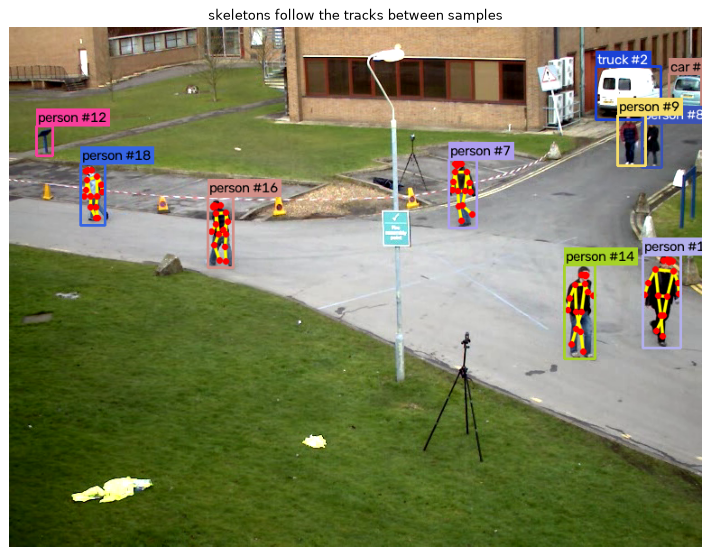

everyone           17 visit(s)
facing the camera  9 visit(s)
black top          14 visit(s)
blue trousers      7 visit(s)
lying down         0 visit(s)

one visit: {'camera': 'street', 'track_id': 6, 'first_seen': '2026-10-08T14:47:06', 'last_seen': '2026-10-08T14:47:11', 'upper_colour': 'black', 'lower_colour': 'black', 'posture_seconds': {'standing': 5.0}, 'arms_seconds': {}, 'facing_camera_seconds': 3.0, 'thumb': None, 'time': 1791460026.347144}


In [18]:
import tempfile

from argus.engine.pipeline import Pipeline
from argus.engine.search import SearchEngine

if POSE_MODELS:
    fast = POSE_MODELS[-1]  # the fastest one here, for the demo
    tmp = Path(tempfile.mkdtemp())
    config = {"model": {"path": str(MODELS / "yolox_nano.onnx"), "conf_threshold": 0.3,
                        "class_agnostic_nms": True},
              "store": {"path": str(tmp / "demo.db")},
              "pose": {"enabled": True, "model": str(MODELS / f"{fast}.onnx"), "min_box_height": 60}}
    pipe = Pipeline.from_config(config, source="street", start_time=time.time(), live=False)
    cap = cv2.VideoCapture(str(DATA / "vtest.avi"))
    for i in range(300):  # 30 s of video
        ok, frame = cap.read()
        result = pipe.process(frame, i / 10)
        if i == 200:
            snapshot = pipe.draw(frame.copy(), result)
    cap.release()
    pipe.close()
    rows = pipe.store.pose_rows()
    print(f"{len(rows)} pose rows stored for 30 s of video ({len({r['track_id'] for r in rows})} people)")
    show(snapshot, titles=["skeletons follow the tracks between samples"], size=8)

    engine = SearchEngine(pipe.store)
    for label, kwargs in (("everyone", {}), ("facing the camera", {"facing": "camera"}),
                          ("black top", {"upper_colour": "black"}),
                          ("blue trousers", {"lower_colour": "blue"}),
                          ("lying down", {"postures": ["lying"]})):
        print(f"{label:18} {len(engine.people(**kwargs))} visit(s)")
    print("\none visit:", engine.people(upper_colour="black")[0].to_dict())

## 6. CLIP: search by description

CLIP has two encoders trained together on image–caption pairs: one for images, one for text.
Both output 512 numbers, so "a red car" and a photo of a red car land close together. Argus
embeds every tracked object (and whole scenes) while recording, then compares a question's
text vector with all of them.

Skipped if the CLIP models aren't exported (`uv run --group export -m argus.engine.export_clip`).

In [19]:
clip_files = [MODELS / n for n in ("clip_image.onnx", "clip_text.onnx", "clip_bpe_vocab.txt.gz")]
if not all(p.exists() for p in clip_files):
    print("CLIP not exported: run `uv run --group export -m argus.engine.export_clip`, then re-run this cell.")
else:
    from argus.engine.clip_onnx import ClipEncoder

    clip = ClipEncoder(*clip_files)
    boxes = agnostic.detect(dog) + YoloxOnnxDetector(MODELS / "yolox_tiny.onnx").detect(image)
    sources = [dog] * len(agnostic.detect(dog)) + [image] * (len(boxes) - len(agnostic.detect(dog)))
    crops = [src[int(b.y1):int(b.y2), int(b.x1):int(b.x2)] for src, b in zip(sources, boxes)]
    SPEED["CLIP image (one crop)"], _ = timed(clip.embed_images, crops[:1])
    image_vectors = clip.embed_images(crops)
    queries = ["a dog", "a bicycle", "a white truck", "a football player", "a ball"]
    text_vectors = np.stack([clip.embed_query(q) for q in queries])
    sims = text_vectors @ image_vectors.T

    show(*crops, titles=[f"{i}: {b.label}" for i, b in enumerate(boxes)], size=1.8)
    fig, ax = plt.subplots(figsize=(1 + 0.7 * len(crops), 3))
    im = ax.imshow(sims, cmap="viridis")
    ax.set_yticks(range(len(queries)), queries)
    ax.set_xticks(range(len(crops)), [str(i) for i in range(len(crops))])
    ax.set_xlabel("crop")
    ax.set_title("text-image similarity: the best crop per question should stand out")
    fig.colorbar(im)
    plt.show()

CLIP not exported: run `uv run --group export -m argus.engine.export_clip`, then re-run this cell.


## 7. Cost on this CPU

YOLOX-Tiny (416)            20.3 ms
YuNet (whole image)         14.1 ms
SFace (one face)             5.6 ms
pose_vitpose_b (one person)   101.6 ms
pose_rtmpose_t (one person)     5.1 ms


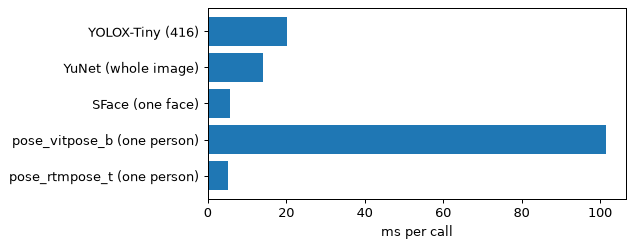

In [20]:
for name, ms in SPEED.items():
    print(f"{name:24} {ms:7.1f} ms")
fig, ax = plt.subplots(figsize=(6, 0.5 + 0.45 * len(SPEED)))
ax.barh(list(SPEED), list(SPEED.values()), color="tab:blue")
ax.invert_yaxis()
ax.set_xlabel("ms per call")
plt.show()

## What next

- **Thresholds** live in the configs (`model.conf_threshold`, `tracking.*`, `faces.*`, `pose.*`): change
  them above, see the effect, then put the value in the config.
- **Licences and sizes**: README, *Models and licences*.
- **Candidate models** (D-FINE-N as a more accurate YOLOX-Tiny replacement, better CLIP weights,
  fire/smoke): `docs/argus/Argus — Model Research.md`. To try a new detector here, it needs the
  same `detect(frame) -> list[Detection]` method as `YoloxOnnxDetector`.